<h1><center>Supervised ML Regression Competition</center></h1>


<img align="center" src="https://compraracciones.com/wp-content/uploads/2021/04/insurance.jpg" style="height:200px" style="width:100px"/>

<hr style="border:2px solid pink"> </hr>

You have been assigned the task of building a model that will predict the insurance cost

You'll find the data in the csv file `insurance`


- target col: "charges"


<hr style="border:2px solid pink"> </hr>


**Guidelines:** 


- train_test_split
    - random state = 42
    - test size = 0.3


- The one who gets the highest r2-score on test data wins


In [125]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import loguniform

from sklearn.model_selection import (train_test_split, cross_val_score, KFold, StratifiedKFold,
                                     validation_curve, learning_curve, GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (root_mean_squared_error, accuracy_score, recall_score, precision_score,
                             f1_score, balanced_accuracy_score, confusion_matrix)

## 1. Initial Data Exploration

Let's start by loading our dataset and taking a first look at it.


In [4]:
insurance = pd.read_csv("insurance.csv")
insurance

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,7725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


## 2. Checking for Missing Values

It's important to know if our data has any missing values. Let's check that next.


In [7]:
insurance.isna().any().any()

np.False_


## 3. Descriptive Statistics

Now, let's move on to some descriptive statistics.

Understanding the distribution of our data is crucial. Let's calculate some descriptive statistics.


In [8]:
insurance.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,15799.570247
std,14.049960,6.098187,1.205493,12559.984021
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,8106.480000
50%,39.000000,30.400000,1.000000,12403.585225
75%,51.000000,34.693750,2.000000,18948.612903
max,64.000000,53.130000,5.000000,64571.074480


In [ ]:
insurance['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [18]:
insurance['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [19]:
insurance['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

## 4. Distribution Analysis

Visualizing the distributions of our features can provide valuable insights. Let's plot the distributions for 'age', 'bmi', and 'charges'.

### Task:
- Plot the histogram for 'age'
- Plot the histogram for 'bmi'
- Plot the histogram for 'charges'


[Text(0.5, 1.0, 'Age Distribution'), Text(0.5, 0, 'Age')]

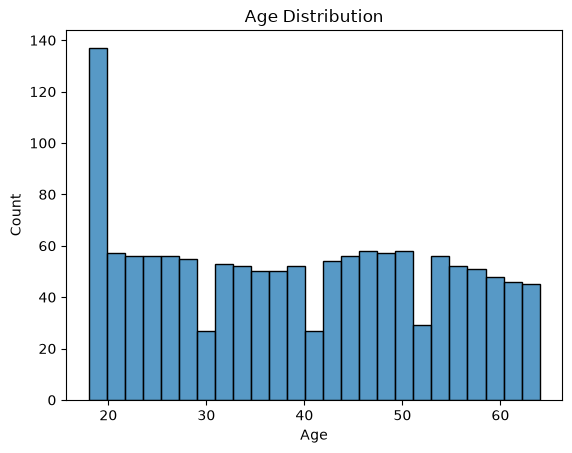

In [72]:
ax = sns.histplot(data=insurance, x='age', bins=25)

ax.set(
    title = 'Age Distribution',
    xlabel = 'Age'
)

[Text(0.5, 1.0, 'Number of Children Distribution'),
 Text(0.5, 0, 'Number of Children')]

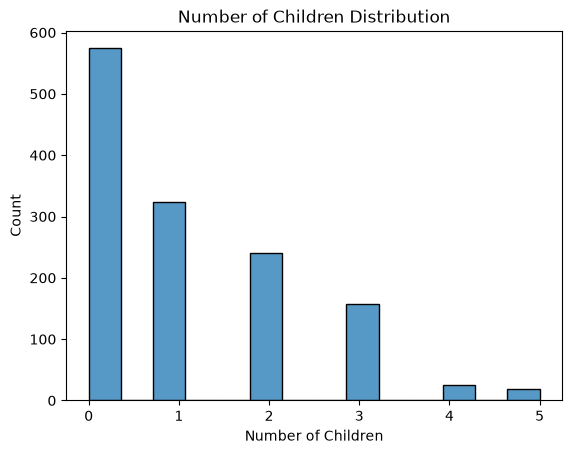

In [69]:
ax = sns.histplot(data=insurance, x='children')

ax.set(
    title = 'Number of Children Distribution',
    xlabel = 'Number of Children'
)

[Text(0.5, 1.0, 'BMI Distribution'), Text(0.5, 0, 'BMI')]

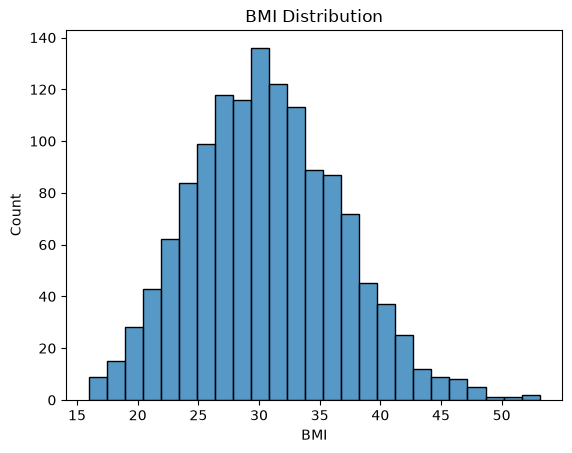

In [26]:
ax = sns.histplot(data=insurance, x='bmi')

ax.set(
    title = 'BMI Distribution',
    xlabel = 'BMI'
)

[Text(0.5, 1.0, 'Charges Distribution'), Text(0.5, 0, 'Charges')]

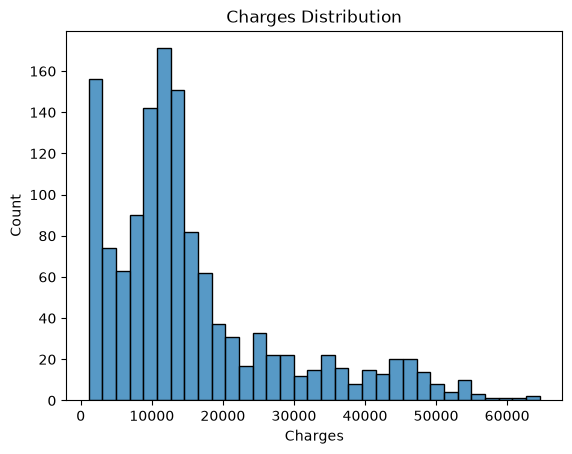

In [27]:
ax = sns.histplot(data=insurance, x='charges')

ax.set(
    title = 'Charges Distribution',
    xlabel = 'Charges'
)

## 5. Relationship Between Variables

Let's explore the relationship between some of our features and the target variable 'charges'. We'll create scatter plots to visualize these relationships.

### Task:
- Create a scatter plot for 'age' vs 'charges'
- Create a scatter plot for 'bmi' vs 'charges'
- Create a scatter plot for 'children' vs 'charges'


[Text(0.5, 1.0, 'Scatter plot between Age and Charges'),
 Text(0.5, 0, 'Age'),
 Text(0, 0.5, 'Charges')]

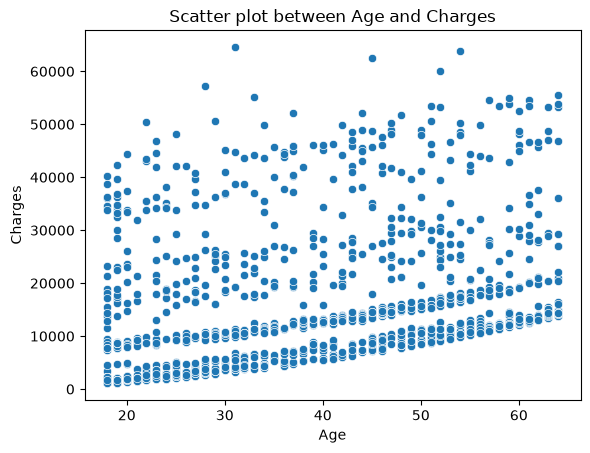

In [29]:
ax = sns.scatterplot(data=insurance, x='age', y='charges')

ax.set(
    title = 'Scatter plot between Age and Charges',
    xlabel = 'Age',
    ylabel = 'Charges'
)

[Text(0.5, 1.0, 'Scatter plot between BMI and Charges'),
 Text(0.5, 0, 'BMI'),
 Text(0, 0.5, 'Charges')]

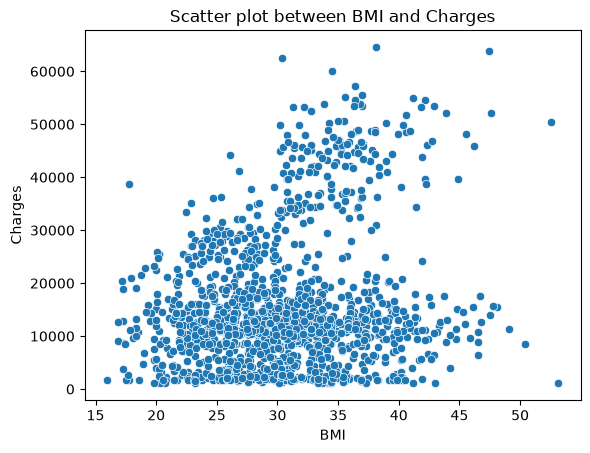

In [30]:
ax = sns.scatterplot(data=insurance, x='bmi', y='charges')

ax.set(
    title = 'Scatter plot between BMI and Charges',
    xlabel = 'BMI',
    ylabel = 'Charges'
)

[Text(0.5, 1.0, 'Scatter plot between number of children and Charges'),
 Text(0.5, 0, 'Number of children'),
 Text(0, 0.5, 'Charges')]

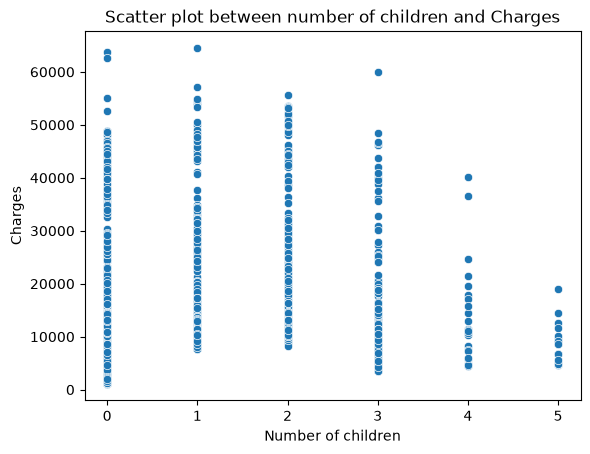

In [31]:
ax = sns.scatterplot(data=insurance, x='children', y='charges')

ax.set(
    title = 'Scatter plot between number of children and Charges',
    xlabel = 'Number of children',
    ylabel = 'Charges'
)

## 6. Categorical Analysis

Let's analyze the categorical features 'sex', 'smoker', and 'region' to see how they relate to 'charges'.

### Task:
- Plot the distribution of 'charges' for different 'sex'
- Plot the distribution of 'charges' for different 'smoker'
- Plot the distribution of 'charges' for different 'region'


[Text(0.5, 1.0, 'Charges Distribution by Sex'), Text(0.5, 0, 'Charges')]

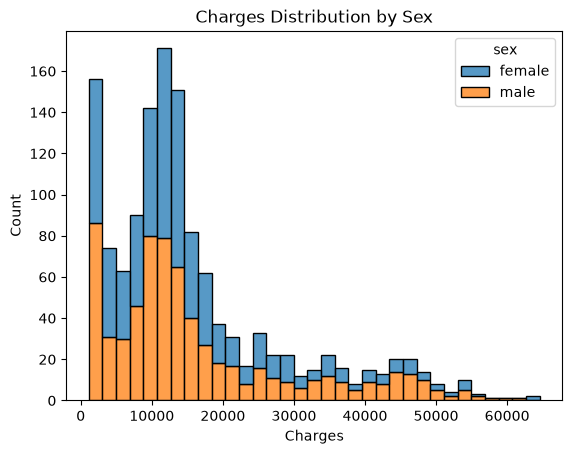

In [41]:
ax = sns.histplot(data=insurance, x='charges', hue="sex", multiple="stack")

ax.set(
    title = 'Charges Distribution by Sex',
    xlabel = 'Charges'
)

[Text(0.5, 1.0, 'Charges Distribution by Smoker Status'),
 Text(0.5, 0, 'Charges')]

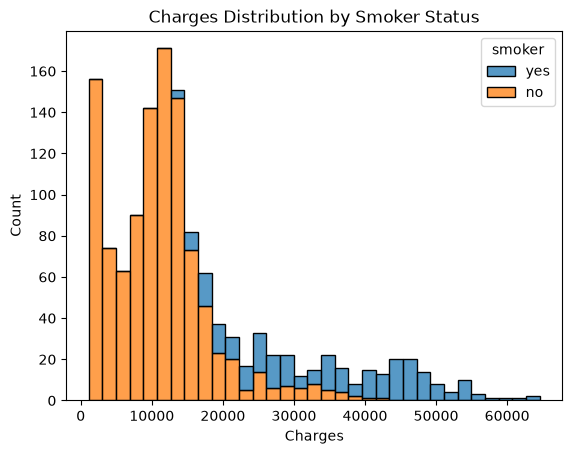

In [42]:
ax = sns.histplot(data=insurance, x='charges', hue="smoker", multiple="stack")

ax.set(
    title = 'Charges Distribution by Smoker Status',
    xlabel = 'Charges'
)

[Text(0.5, 1.0, 'Charges Distribution by Region'), Text(0.5, 0, 'Charges')]

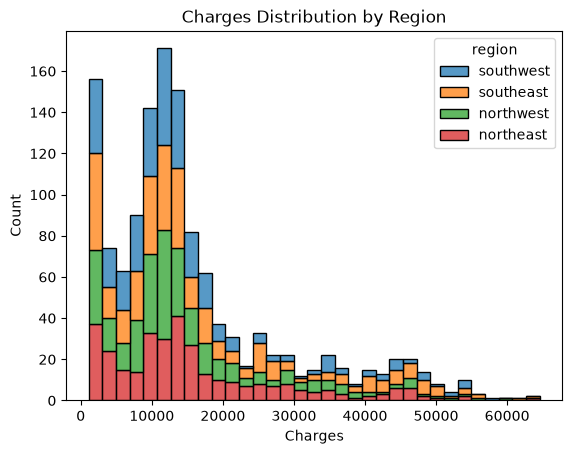

In [40]:
ax = sns.histplot(data=insurance, x='charges', hue="region", multiple="stack")

ax.set(
    title = 'Charges Distribution by Region',
    xlabel = 'Charges'
)

## 7. Correlation Analysis

To understand how our numerical features relate to each other and to the target variable, let's calculate and visualize the correlation matrix.

### Task:
- Calculate the correlation matrix for the dataset
- Visualize the correlation matrix using a heatmap


In [44]:
numeric_columns = insurance.select_dtypes(include="number")
numeric_columns

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,7725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


In [45]:
correlation_matrix = numeric_columns.corr()
correlation_matrix

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.291786
bmi,0.109272,1.000000,0.012759,0.194897
children,0.042469,0.012759,1.000000,0.120829
charges,0.291786,0.194897,0.120829,1.000000


[Text(0.5, 1.0, 'Correlation Matrix')]

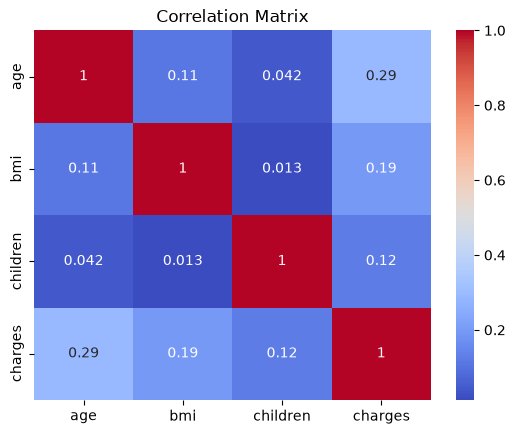

In [50]:
ax = sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')

ax.set(
    title = 'Correlation Matrix'
)

# Modelling time!

## 1. Find the Naive Baseline

Before we build any models, let's establish a naive baseline. This will help us understand how well our models perform compared to a simple approach. In regression problems, the naive baseline is often the mean of the target variable.

### Task:
- Calculate the mean of the target variable 'charges'
- Explain why it's important to establish a naive baseline


In [53]:
mean_charges = insurance['charges'].mean()
mean_charges

np.float64(15799.570247204036)

It is important to establish a naive baseline to compare its performance with those of the algorithms to be trained. 

## 2. Initial Modelling Without GridSearch or Pipeline

Let's build a simple linear regression model without any feature engineering, grid search, or pipeline. This will serve as our initial baseline for comparison.

### Task:
- Encode the text columns `sex`, `smoker` and `region` first: a model only accepts numbers. `pd.get_dummies(..., drop_first=True)` is enough here.
- Split the data into training and test sets, using the guidelines at the top (`test_size=0.3`, `random_state=42`).
- Train a simple linear regression model.
- Evaluate its performance using regression metrics.
- Write it down as a markdown below so you can keep track. This is a scientific experiment.


In [66]:
X = pd.get_dummies(insurance.drop(columns="charges"), drop_first=True)
y = insurance["charges"]
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False


In [67]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [68]:
lin_reg = LinearRegression().fit(X_train, y_train)

y_train_pred = lin_reg.predict(X_train)
y_test_pred = lin_reg.predict(X_test)

print('R^2 train: ', r2_score(y_train, y_train_pred))
print('R^2 test: ', r2_score(y_test, y_test_pred))
print('MSE test: ', mean_squared_error(y_test, y_test_pred))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_test_pred)))
print('MAE test: ', mean_absolute_error(y_test, y_test_pred))

R^2 train:  0.7019233969325942
R^2 test:  0.7263438163107672
MSE test:  43014061.454674505
RMSE test: 6558.510612530447
MAE test:  4996.264726691542


## 3. Feature Engineering

Now, let's brainstorm and create some new features to see if we can improve the model's performance.

### Questions:
1. Should we create an interaction feature between 'bmi' and 'children'? 
2. Should we create age groups to see if the model improves by categorizing age?
3. Should we create a high-risk indicator based on 'smoker' and 'bmi'?

- Remember nothing is set in stone, this is your experiment, your hypothesis. You may not need to, but its important to explore these questions.

### Task:
- Create new features based on the questions above.
- Explain the rationale behind each feature.



1. There is almost no correlation between 'bmi' and 'children'. So, I do not believe that creating an interaction feature would benefit the model.
2. Except for ages under 20, the age distribution is practically uniform. Thus, I do not think that creating age groups would provide new information to the model. 
3. From the plot below, one can observe that smokers with obesity-range BMI have the highest charges. Then, we can create a binary column: 1 for smokers with BMI ≥ 30, otherwise 0.

[Text(0.5, 1.0, 'Scatter plot between BMI and Charges by Smoker Status'),
 Text(0.5, 0, 'BMI'),
 Text(0, 0.5, 'Charges')]

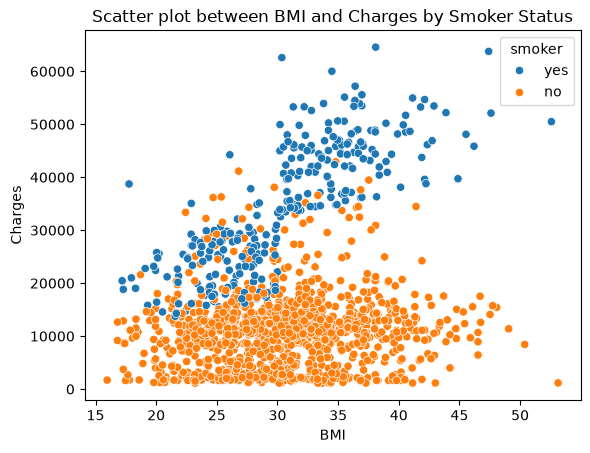

In [74]:
ax = sns.scatterplot(data=insurance, x='bmi', y='charges', hue='smoker')

ax.set(
    title = 'Scatter plot between BMI and Charges by Smoker Status',
    xlabel = 'BMI',
    ylabel = 'Charges'
)

In [78]:
X_feature= X.copy()

X_feature["high_risk"] = (
    (X["smoker_yes"] == True) & (X["bmi"] >= 30)
).astype(int)

X_feature.sample(10)

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,high_risk
496,31,23.60,2,False,False,False,False,True,0
346,33,35.75,2,True,False,False,True,False,0
1300,45,30.36,0,True,True,False,True,False,1
876,49,27.10,1,False,False,False,False,True,0
261,20,26.84,1,False,True,False,True,False,0
448,40,29.60,0,False,False,False,False,True,0
822,18,31.13,0,False,False,False,True,False,0
1164,41,28.31,1,False,False,True,False,False,0
147,51,37.73,1,False,False,False,True,False,0
92,59,29.83,3,True,True,False,False,False,0


## 4. Modelling with Feature Engineering

Now that we have new features, let's see if they improve our model's performance.
Did it improve the performance? Yes? No? Why

### Task:
- Split the data into training and test sets
- Train a linear regression model with the new features
- Evaluate its performance using regression metrics


In [80]:
X_feat_train, X_feat_test, y_train, y_test = train_test_split(X_feature, y, test_size=0.3, random_state=42)

lin_reg_feat = LinearRegression().fit(X_feat_train, y_train)

y_feat_train_pred = lin_reg_feat.predict(X_feat_train)
y_feat_test_pred = lin_reg_feat.predict(X_feat_test)

print('R^2 train: ', r2_score(y_train, y_train_pred))
print('R^2 test: ', r2_score(y_test, y_test_pred))
print('MSE test: ', mean_squared_error(y_test, y_test_pred))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_test_pred)))
print('MAE test: ', mean_absolute_error(y_test, y_test_pred))

R^2 train:  0.7019233969325942
R^2 test:  0.7263438163107672
MSE test:  43014061.454674505
RMSE test: 6558.510612530447
MAE test:  4996.264726691542


The performance remained unchanged. My hypothesis is because the high-risk indicator represented information that was already available in `bmi` and `smoker`.

## 5. Modelling with Pipeline and Grid Search

Now, let's see how using pipelines can simplify our workflow and prevent data leakage. We'll also use GridSearchCV to find the best hyperparameters.

### Task:
- Create a pipeline that starts from the raw columns: a `ColumnTransformer` that one-hot encodes the text columns and scales the numeric ones, followed by a `Ridge` regression
- Plain `LinearRegression` has no hyperparameter worth tuning; `Ridge` has `alpha`, the strength of its regularisation. Define a grid of `alpha` values (for example from 0.01 to 100)
- Use `GridSearchCV` on the training set to find the best `alpha`, then evaluate the best model on the test set once


In [112]:
X_raw = insurance.drop(columns="charges")
y_raw = insurance["charges"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_raw, y_raw, test_size=0.3, random_state=42)

categorical = ["sex", "smoker", "region"]
numeric = [c for c in X_raw.columns if c not in categorical]

preprocess = ColumnTransformer([
    ("cat", make_pipeline(OneHotEncoder(drop="if_binary", handle_unknown="ignore")), categorical),
    ("num", MinMaxScaler(), numeric),
])

pipe = Pipeline([
    ("prep", preprocess),
    ("model", Ridge(alpha=0.001)),
])

param_grid = {
    "model__alpha": np.logspace(-3, 2,num=10),
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_root_mean_squared_error")
grid.fit(Xr_train, yr_train)

print("Best settings:", grid.best_params_)
print(f"Best cross-validated RMSE: {-grid.best_score_:,.0f}")

Best settings: {'model__alpha': np.float64(0.001)}
Best cross-validated RMSE: 6,938


In [113]:
results = pd.DataFrame(grid.cv_results_)
results["rmse"] = -results["mean_test_score"]
# results.pivot(index="param_model__alpha", values="rmse").round(0)
results[['param_model__alpha','rmse']]

,param_model__alpha,rmse
0,0.001000,6938.150881
1,0.003594,6938.153454
2,0.012915,6938.162861
3,0.046416,6938.198757
4,0.166810,6938.354433
5,0.599484,6939.244956
6,2.154435,6946.182055
7,7.742637,7003.279898
8,27.825594,7362.398628
9,100.000000,8666.730020


## 6. Trying Another Model with Pipeline

Let's try a model that can capture non-linear patterns, such as the smoker and BMI interaction you may have spotted.

### Task:
- Create a pipeline with the same preprocessing and a `KNeighborsRegressor` (tune `n_neighbors`) or a `DecisionTreeRegressor` (tune `max_depth` and `min_samples_leaf`)
- Define a parameter grid for grid search
- Use GridSearchCV to find the best parameters and evaluate the model

Tomorrow's lesson introduces ensembles. Come back afterwards and try `RandomForestRegressor` and `GradientBoostingRegressor` in the same pipeline: they usually win this challenge.

In [ ]:
pipe_dt = Pipeline([
    ("prep", preprocess),
    ("model", KNeighborsRegressor()),
])

param_grid_dt = {
    "model__n_neighbors": [1, 3, 5, 10, 20, 40],
}
grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=5, scoring="neg_root_mean_squared_error")
grid_dt.fit(Xr_train, yr_train)

print("Best settings:", grid_dt.best_params_)
print(f"Best cross-validated RMSE: {-grid_dt.best_score_:,.0f}")

Best settings: {'model__n_neighbors': 3}
Best cross-validated RMSE: 6,541


In [ ]:
results = pd.DataFrame(grid_dt.cv_results_)
results["rmse"] = -results["mean_test_score"]
results[['param_model__n_neighbors','rmse']]

,param_model__n_neighbors,rmse
0,1,7582.172449
1,3,6541.455222
2,5,6657.735801
3,10,6909.354468
4,20,7459.191698
5,40,8690.070507


In [ ]:
pipe_dt = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeRegressor()),
])

param_grid_dt = {
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 3, 4, 5, 10, 20]
}
grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=5, scoring="neg_root_mean_squared_error")
grid_dt.fit(Xr_train, yr_train)

print("Best settings:", grid_dt.best_params_)
print(f"Best cross-validated RMSE: {-grid_dt.best_score_:,.0f}")

Best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 4}
Best cross-validated RMSE: 5,065


In [128]:
results_dt = pd.DataFrame(grid_dt.cv_results_)
results_dt["rmse"] = -results_dt["mean_test_score"]
results_dt.pivot(index="param_model__max_depth", columns="param_model__min_samples_leaf", values="rmse").round(0)

param_model__min_samples_leaf,1,5,20
param_model__max_depth,,,
NaN,6964.0,5347.0,5123.0
3,5386.0,5386.0,5386.0
4,5214.0,5209.0,5210.0
5,5242.0,5069.0,5134.0
6,5424.0,5112.0,5104.0
8,6324.0,5261.0,5123.0
10,6712.0,5346.0,5123.0


## 7. GridSearch with Several Models

Finally, let's compare several models using GridSearchCV to find the best one.

### Task:
- Define multiple models and their parameter grids
- Use GridSearchCV to find the best model and parameters

*Hint:* `GridSearchCV` accepts a list of grids, and the model step itself can be one of the parameters:

```python
param_grid = [
    {"model": [Ridge()], "model__alpha": [0.1, 1, 10]},
    {"model": [DecisionTreeRegressor(random_state=42)], "model__max_depth": [3, 5, 8]},
]
```

In [139]:
pipe_sm = Pipeline([
    ("prep", preprocess),
    ("model", Ridge()),
])

param_grid_sm = [
    {"model": [Ridge()], "model__alpha": [0.1, 1, 10]},
    {"model": [KNeighborsRegressor()], "model__n_neighbors": [1, 3, 5, 10, 20, 40]},
    {"model": [DecisionTreeRegressor(random_state=42)], "model__max_depth": [3, 4, 5, 6, 8, 10, None],
        "model__min_samples_leaf": [1, 2, 3, 4, 5, 10, 20]}
]

grid_sm = GridSearchCV(pipe_sm, param_grid_sm, cv=5, scoring="neg_root_mean_squared_error")
grid_sm.fit(Xr_train, yr_train)

print("Best settings:", grid_sm.best_params_)
print(f"Best cross-validated RMSE: {-grid_sm.best_score_:,.0f}")

Best settings: {'model': DecisionTreeRegressor(random_state=42), 'model__max_depth': 5, 'model__min_samples_leaf': 4}
Best cross-validated RMSE: 5,065


# Machine Learning: Master Challenge

## 8. Calculating Potential Cost or Loss

### Challenge:
Now that you've built and optimized your models, it's time for the final challenge! Your task is to minimize the Root Mean Squared Error (RMSE) of your model's predictions and calculate the potential financial impact of your model's errors.

### Task:
1. Calculate the RMSE of your final model's predictions.
2. Break down the errors into underestimation and overestimation.
3. Calculate the total potential cost or loss to the company.
4. Compete with your classmates to see who can achieve the lowest RMSE and financial impact!

### Explanation:
The RMSE provides an estimate of the average error in your model's predictions. We will also analyze the errors by categorizing them into underestimations and overestimations to understand their financial impact.

#### Steps to Calculate Underestimation and Overestimation Errors:

1. **Calculate RMSE**:
   - Use the `mean_squared_error` function from `sklearn.metrics` and pass your actual values (`y_test`) and predicted values (`y_pred_final`) to it.
   - Take the square root of the result to get the RMSE, or use `root_mean_squared_error` directly.
   
2. **Calculate Underestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are greater than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the actual and predicted charges.
   - Sum these differences to get the total underestimation error.

3. **Calculate Overestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are less than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the predicted and actual charges.
   - Sum these differences to get the total overestimation error.

4. **Calculate Total Potential Cost or Loss**:
   - Add the total underestimation error and the total overestimation error to get the total potential cost or loss. This is the sum of the absolute errors, so it is the MAE multiplied by the number of test rows.

### Let's see who can build the best model!

#### Detailed Instructions:

1. **Calculate RMSE**:
   - Use `mean_squared_error` with `y_test` and `y_pred_final`.
   - Use `np.sqrt` to take the square root of the result.

2. **Calculate Underestimation Error**:
   - Use a boolean condition to filter `y_test` values that are greater than `y_pred_final`.
   - Subtract the predicted values from the actual values for these instances.
   - Sum these differences.

3. **Calculate Overestimation Error**:
   - Use a boolean condition to filter `y_test` values that are less than `y_pred_final`.
   - Subtract the actual values from the predicted values for these instances.
   - Sum these differences.

4. **Calculate Total Potential Cost or Loss**:
   - Add the results of the underestimation error and overestimation error to get the total potential cost or loss.

### Example Walkthrough:

1. **Calculate RMSE**:
   - `rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))`
   - This gives you the average prediction error in dollars.

2. **Calculate Underestimation Error**:
   - `underestimation_error = np.sum(y_test[y_test > y_pred_final] - y_pred_final[y_test > y_pred_final])`
   - This gives you the total amount by which the model undercharged.

3. **Calculate Overestimation Error**:
   - `overestimation_error = np.sum(y_pred_final[y_test < y_pred_final] - y_test[y_test < y_pred_final])`
   - This gives you the total amount by which the model overcharged.

4. **Calculate Total Potential Cost or Loss**:
   - `total_potential_loss = underestimation_error + overestimation_error`
   - This gives you the total financial impact of the model's errors.

### Leaderboard:
Post your RMSE score and total potential cost or loss on the class leaderboard. The student with the lowest RMSE and total potential cost or loss wins bragging rights

### Post Your Results 

- Name
- Model Type
- RMSE
- Underestimation Error
- Overestimation Error
- Total Potential Cost/Loss

In [145]:
best_regressor = grid_sm.best_estimator_
y_pred_final = best_regressor.predict(Xr_test)

rmse = np.sqrt(mean_squared_error(yr_test, y_pred_final))
rmse

np.float64(4525.854523765931)

In [147]:
underestimation_error = np.sum(y_test[y_test > y_pred_final] - y_pred_final[y_test > y_pred_final])
underestimation_error

np.float64(477490.7133235571)

In [148]:
overestimation_error = np.sum(y_pred_final[y_test < y_pred_final] - y_test[y_test < y_pred_final])
overestimation_error

np.float64(594130.5544523658)

In [149]:
total_potential_loss = underestimation_error + overestimation_error
total_potential_loss

np.float64(1071621.267775923)

## Conclusion

Congratulations! You've completed the lab. Here's a summary of what we've covered:
1. Established a naive baseline using the mean of the target variable.
2. Built an initial linear regression model without any feature engineering or optimization.
3. Performed feature engineering to create new, potentially useful features.
4. Used pipelines and GridSearchCV to optimize the model.
5. Evaluated the final model's performance using RMSE to understand its business impact.

By following these steps, you now have a robust understanding of how to approach a regression problem, from initial exploration to model optimization and business impact assessment. Great job!
